# Chương 4 bài 1 Cây quyết định và rừng cây Titanic

**Nguồn:** Lab phân lớp, mục 2.1.3, trang 7

**Đề bài:** Xây dựng cây quyết định và rừng cây trên dữ liệu Titanic.

Code triển khai bài tập theo dữ liệu đã cung cấp; không phải đoạn chép nguyên văn bài mẫu.

In [1]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data').is_dir() and (p / 'README.md').is_file())
DATA = ROOT / 'data'
OUT = ROOT / 'ket_qua' / 'C4_BT01_Cay_Rung_Titanic'
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'figure.figsize': (8, 4)})

def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140, bbox_inches='tight')
    plt.show()

def save_summary(values):
    (OUT / 'tom_tat.json').write_text(
        json.dumps(values, ensure_ascii=False, indent=2), encoding='utf-8'
    )


## 1 Nạp và chọn đặc trưng

In [2]:
df = pd.read_csv(DATA / 'titanic/train.csv')
num_cols = ['Pclass','Age','SibSp','Parch','Fare']
cat_cols = ['Sex','Embarked']
X = df[num_cols + cat_cols]
y = df['Survived']
print(df.shape)
print('Missing:', X.isna().sum().to_dict())
# Ignore PassengerId, Name, Ticket, Cabin; test.csv has no ground-truth Survived.

(891, 12)
Missing: {'Pclass': 0, 'Age': 177, 'SibSp': 0, 'Parch': 0, 'Fare': 0, 'Sex': 0, 'Embarked': 2}


## 2 Chia dữ liệu

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Test classes:', y_test.value_counts().to_dict())

Train: (712, 7) Test: (179, 7)
Test classes: {0: 110, 1: 69}


## 3 Tiền xử lý theo tập train

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
preprocess = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), num_cols),
    ('category', Pipeline([
        ('fill', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_cols)
])
X_train_ready = preprocess.fit_transform(X_train)
X_test_ready = preprocess.transform(X_test)
feature_names = list(preprocess.get_feature_names_out())

## 4 Tạo mô hình

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
models = {
    'DecisionTree': DecisionTreeClassifier(max_depth=4, random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=100, max_depth=8,
                                            random_state=42, n_jobs=2)
}

## 5 Huấn luyện và đánh giá

DecisionTree 
               precision    recall  f1-score   support

           0       0.77      0.95      0.85       110
           1       0.86      0.55      0.67        69

    accuracy                           0.79       179
   macro avg       0.82      0.75      0.76       179
weighted avg       0.81      0.79      0.78       179

RandomForest 
               precision    recall  f1-score   support

           0       0.80      0.90      0.85       110
           1       0.80      0.65      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.78       179
weighted avg       0.80      0.80      0.80       179

       model  accuracy  precision  recall     f1  roc_auc  recall_negative  balanced_accuracy  average_precision
DecisionTree    0.7933     0.8636  0.5507 0.6726   0.8292           0.9455             0.7481             0.7774
RandomForest    0.8045     0.8036  0.6522 0.7200   0.8419           0.9000             0.7

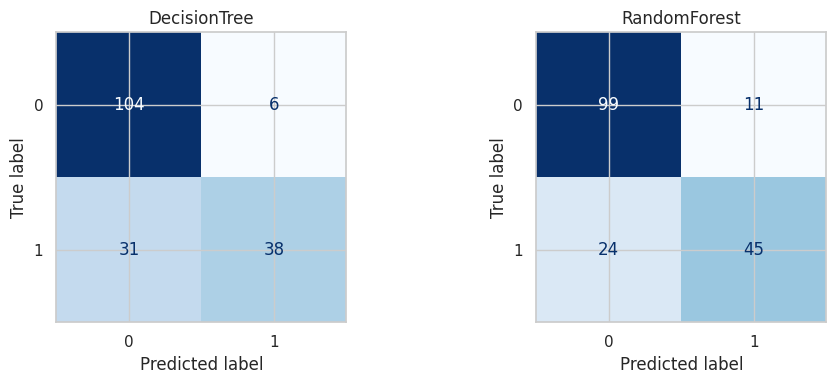

In [6]:
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             classification_report, ConfusionMatrixDisplay)
rows = []
for name, model in models.items():
    model.fit(X_train_ready, y_train)
    pred = model.predict(X_test_ready)
    prob = model.predict_proba(X_test_ready)[:, list(model.classes_).index(1)]
    rows.append({'model':name, 'accuracy':float(accuracy_score(y_test,pred)),
                 'precision':float(precision_score(y_test,pred,zero_division=0)),
                 'recall':float(recall_score(y_test,pred,zero_division=0)),
                 'f1':float(f1_score(y_test,pred,zero_division=0)),
                 'roc_auc':float(roc_auc_score(y_test,prob)),
                 'recall_negative':float(recall_score(y_test,pred,pos_label=0,zero_division=0)),
                 'balanced_accuracy':float(balanced_accuracy_score(y_test,pred)),
                 'average_precision':float(average_precision_score(y_test,prob))})
    print(name, '\n', classification_report(y_test,pred,zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model,X_test_ready,y_test,ax=ax,
                                         cmap='Blues',colorbar=False)
    ax.set_title(name)
save_fig('01_confusion_matrices.png')
results = pd.DataFrame(rows)
print(results.round(4).to_string(index=False))
results.to_csv(OUT / 'metrics.csv',index=False)
save_summary({'train_rows':len(y_train),'test_rows':len(y_test),
              'positive_label':1,'metrics':rows})

## 6 Vẽ cây và độ quan trọng đặc trưng

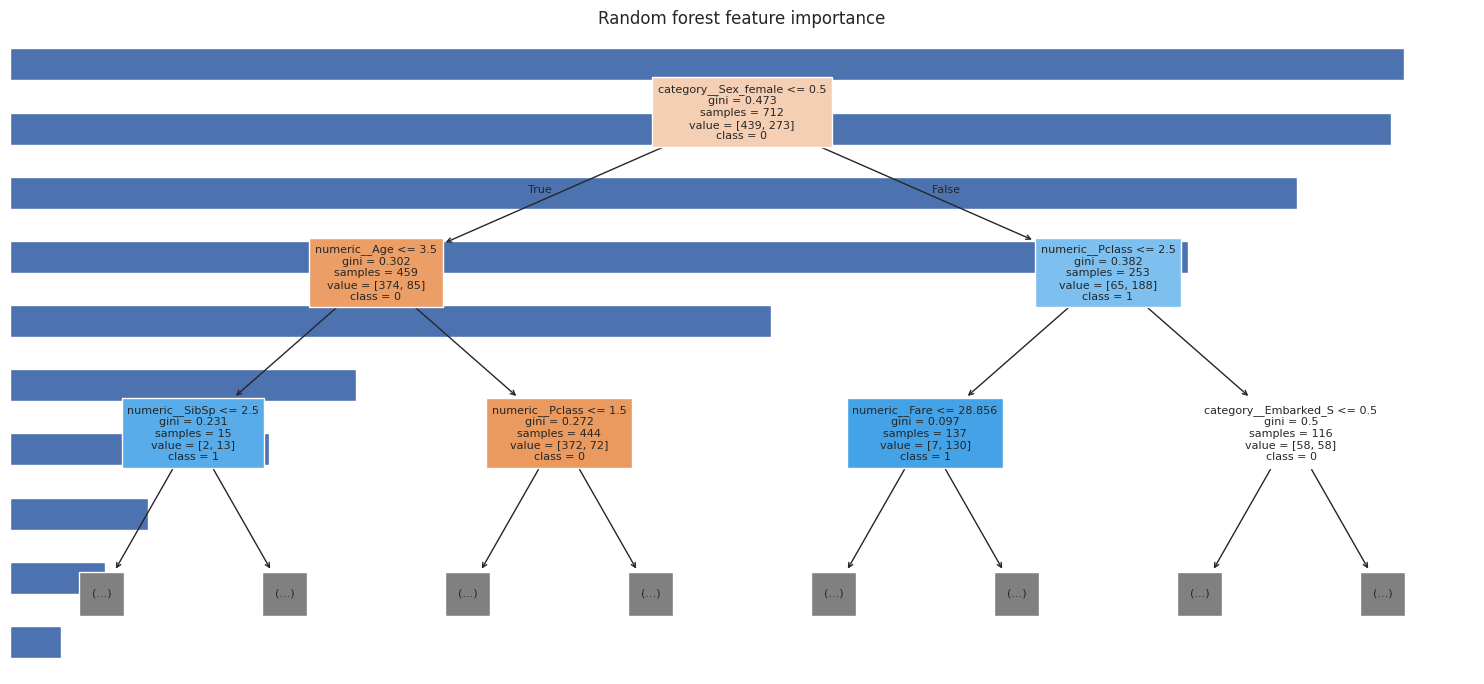

In [7]:
from sklearn.tree import plot_tree
plt.figure(figsize=(15, 7))
plot_tree(models['DecisionTree'], feature_names=feature_names,
          class_names=['0','1'], filled=True, max_depth=2, fontsize=8)
plt.title('Decision tree - first 3 levels (display truncated)')
save_fig('02_cay_quyet_dinh.png')
importance = pd.Series(models['RandomForest'].feature_importances_,
                       index=feature_names).sort_values(ascending=False)
importance.to_csv(OUT / 'feature_importance.csv')
importance.head(12).sort_values().plot.barh(title='Random forest feature importance')
save_fig('03_feature_importance.png')

## Nhận xét và giới hạn
Thông số mô hình được đặt trước để minh họa, chưa phải kết quả tối ưu siêu tham số. Imputer/encoder chỉ fit trên train. Cây hiển thị chỉ ba mức đầu; mô hình đã học có thể sâu hơn. Feature importance không biểu thị quan hệ nhân quả. So sánh hai mô hình trên cùng tập test, không kết luận ưu thế phổ quát từ một phép chia. Chỉ chia train.csv có nhãn; không dùng gender_submission.csv làm nhãn thật.